In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sys
import os
import seaborn as sns

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.insert(0, src_dir)

# Now you can import the module
import standardised_pipeline_utils
from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from scipy.stats import pearsonr
from scipy.cluster.hierarchy import fcluster
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram
from sklearn.utils import resample
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform

# Spearman

In [ ]:
spearman = load('data/full_spearman.joblib')
spearman

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AACSP1,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.259988,0.233929,-0.116902,0.230195,0.000000,-0.142924,0.000000,0.000000,0.000000,0.0,...,0.139395,0.000000,0.000000,0.000000,0.000000,0.000000,0.225174,0.170703,0.000000,0.123180
AAAS,0.000000,0.000000,0.000000,0.000000,0.121819,0.111012,0.000000,0.000000,-0.166863,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.109546,0.000000,0.000000,-0.127864,0.114503
AACS,0.000000,0.000000,0.000000,0.000000,0.000000,-0.147828,0.000000,0.000000,0.446383,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.127329,0.103151,0.000000,0.000000,0.000000,-0.157370,-0.153830,0.197541,0.120025,0.0,...,0.218814,0.000000,0.117859,0.117173,0.000000,0.000000,0.000000,0.000000,0.209716,0.000000
AAK1,0.182794,0.179434,0.000000,0.000000,0.000000,-0.114290,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.144951,0.000000,0.000000,0.000000,0.239220,0.291094,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RUVBL2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.106743,-0.106265,0.0,...,0.000000,0.000000,0.000000,0.000000,0.150135,0.000000,0.000000,0.000000,0.000000,0.000000
RYBP,0.106975,0.000000,0.000000,0.000000,0.000000,0.000000,-0.208265,0.189727,0.000000,0.0,...,0.000000,0.183956,0.000000,0.000000,0.218500,0.000000,0.000000,-0.125549,0.156089,0.000000
S100A10,-0.295469,-0.275389,0.129749,-0.177183,0.000000,0.120204,0.359290,-0.332902,0.000000,0.0,...,0.000000,-0.147222,0.000000,0.000000,-0.194365,0.000000,0.000000,0.235213,-0.181334,0.000000


In [ ]:
transcriptomics_filtered = load('data/transcriptomics_kde_filtered.joblib')
transcriptomics_filtered

In [ ]:
#Remove genes filtered out in the filtering procedure
spearman = spearman[transcriptomics_filtered.columns]
spearman

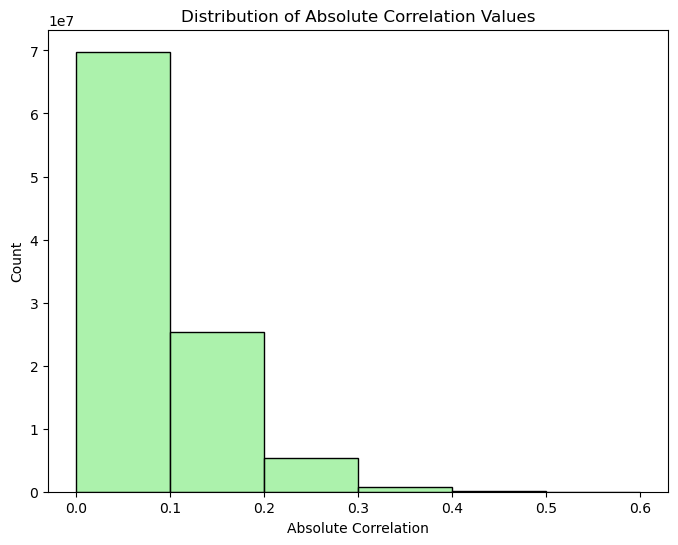

In [ ]:
abs_values = spearman.abs().values.flatten()

#bins (0–0.1, 0.1–0.2, 0.2–0.3, ..., 0.9)
bins = np.arange(0, 0.7, 0.1)

plt.figure(figsize=(8, 6))
sns.histplot(abs_values, bins=bins, kde=False, color='lightgreen', edgecolor='black')
plt.xlabel('Absolute Correlation')
plt.ylabel('Count')
plt.title('Distribution of Absolute Correlation Values')
plt.xticks(bins)  # Ensure the x-axis shows the bin edges
plt.show()


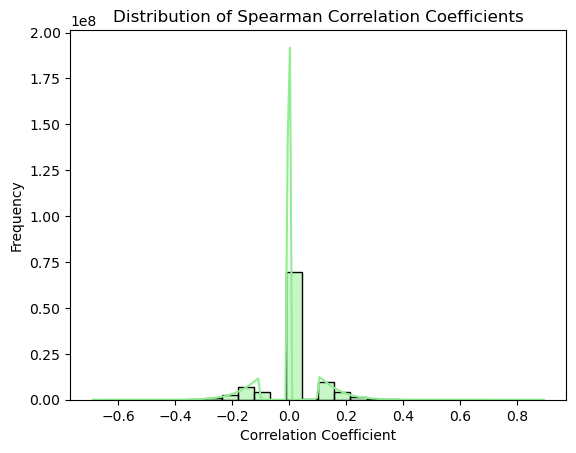

In [ ]:
data = spearman.values.flatten()

# Create a histogram with a kernel density estimate (KDE) in skyblue
sns.histplot(data, color='lightgreen', kde=True)

# Optional customizations
plt.title("Distribution of Spearman Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")

# Display the plot
plt.show()

filter out zeros

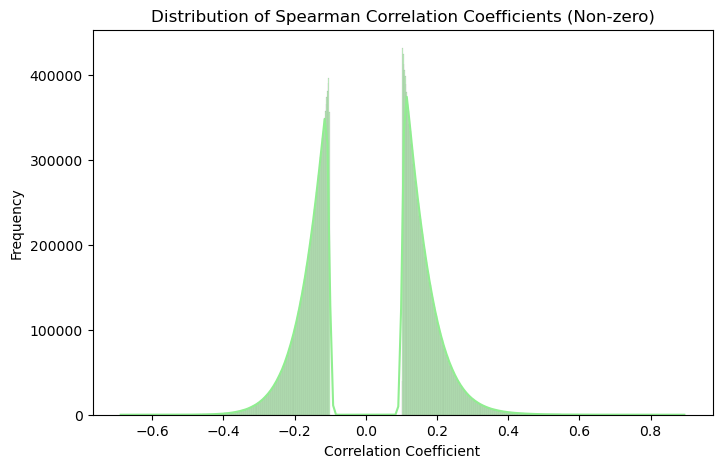

In [ ]:
# Filter out exact zeros or near-zeros
non_zero_data = data[np.isclose(data, 0, atol=1e-10) == False]

plt.figure(figsize=(8, 5))
sns.histplot(non_zero_data, color='lightgreen', kde=True)
plt.title("Distribution of Spearman Correlation Coefficients (Non-zero)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")
plt.show()

### Plot protein - # correlated genes

how many zeros


In [ ]:
zero_counts = (spearman == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (spearman.abs() > t).sum(axis=1) for t in thresholds}

In [ ]:
print_summary()

          Zero Correlations  Correlated > 0.1  Correlated > 0.2  \
proteins                                                          
A2M                   15713             10282              2847   
AAAS                  21163              4832               240   
AACS                  22157              3838               121   
AAGAB                 17925              8070               872   
AAK1                  15616             10379              2799   
...                     ...               ...               ...   
RUVBL2                21625              4370               155   
RYBP                  15113             10882              2730   
S100A10               11266             14729              6753   
S100A11               14069             11926              3535   
S100A13               16522              9473              1810   

          Correlated > 0.3  
proteins                    
A2M                    372  
AAAS                     0  
AACS        

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

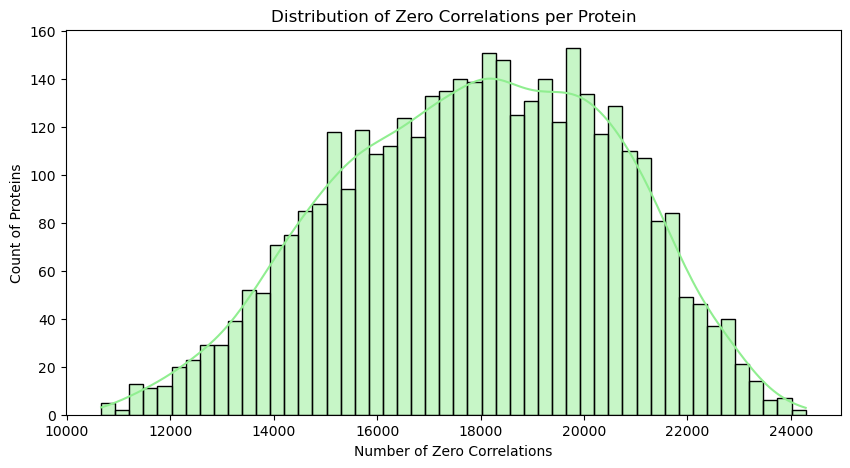

In [ ]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, color ="lightgreen", kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

## Above 0.1 absolute correlation

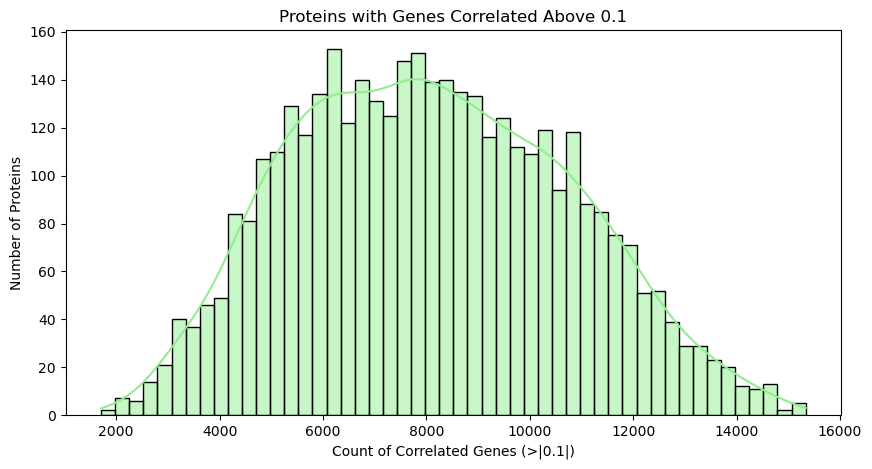

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, color ="lightgreen", kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

## Above 0.2 absolute correlation

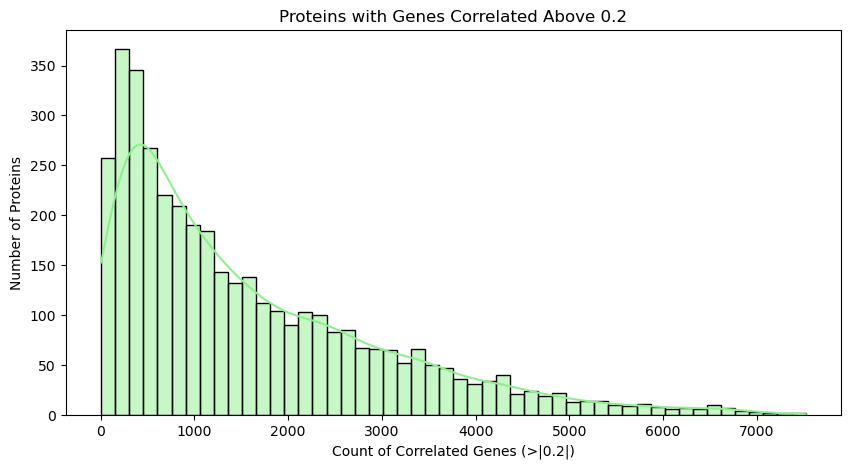

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50,color ="lightgreen",  kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

## Above 0.3 absolute correlation

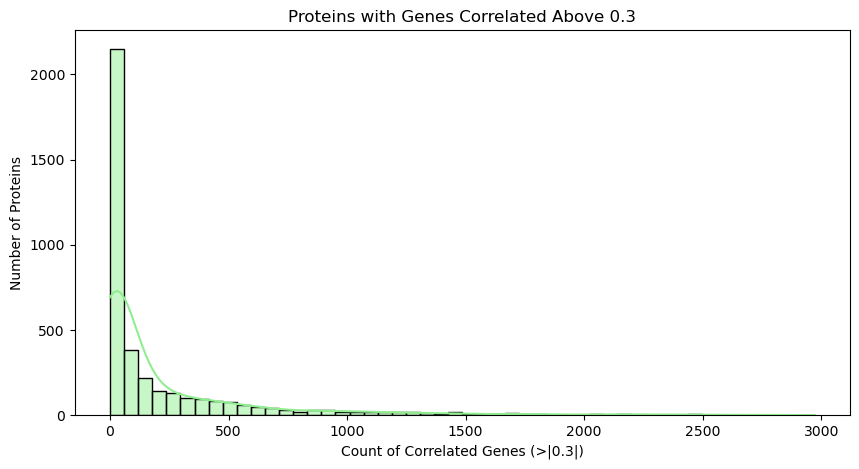

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50,color ="lightgreen",  kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()